*Mathematical Foundations of Robotics · Chapter 7 — Trajectory Generation*

# 7.1 Joint-Space Trajectories: Paths, Smoothness and Polynomials

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/07-trajectory-generation/7.1-joint-space-polynomial-trajectories.ipynb)

A robot does not jump between configurations: it must be told, hundreds of times per second, where each joint
should be *now*. A **path** is only the geometric curve to be followed; a **trajectory** attaches a time law to it
and supplies the position, velocity and acceleration setpoints that the servo loops track. This notebook builds the
simplest and most widely used trajectories — polynomials in time — in joint space. We derive the cubic and quintic
from their boundary conditions, explain which smoothness a physical robot needs and why, show how the peak velocity,
acceleration and jerk scale with the duration, and execute a quintic between two configurations of a real
**UR5e** arm in MuJoCo.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 7 (§7.1–7.3: introduction, general considerations, joint-space schemes with cubic and higher-order polynomials) |
| **Parallel reading** | Lynch & Park Ch. 9 (trajectory generation: paths, time scaling, polynomial time scaling) · Siciliano et al. Ch. 4 (trajectory planning) · Corke *RVC* Ch. 3 (time and motion) |
| **Lectures** | *No lecture of the verified course index treats trajectory generation* — see the [chapter README](README.md) for what to watch instead |
| **Prerequisites** | Derivatives of polynomials and small linear systems ([M5 Calculus](../../math-primer/M5-calculus-and-differential-equations.md), [M2 Matrices](../../math-primer/M2-matrices-and-linear-maps.md)) |
| **Study time** | about 3 hours |

## Learning objectives

1. Distinguish a **path** from a **trajectory**, and state the smoothness (continuity of position, velocity, acceleration and jerk) that a manipulator trajectory should have, with the physical reason for each.
2. **Derive** the coefficients of the cubic and quintic polynomials from their boundary conditions, as a linear system solved both symbolically and numerically.
3. Compute the position, velocity, acceleration and jerk of a polynomial trajectory, and its peak values, in closed form.
4. Explain how the peaks scale with the duration $T$ ($1/T$, $1/T^2$, $1/T^3$) and compute the **minimum duration** that respects given velocity and acceleration limits.
5. Explain why the quintic is the *minimum-jerk* rest-to-rest polynomial and verify the property numerically.
6. Coordinate several joints so that they start and stop together, and recognise that the resulting motion is a straight line **in joint space**, not in Cartesian space.
7. Generate and check a joint-space trajectory for a real UR5e in MuJoCo.

## Contents

1. [From a task to a trajectory](#1.-From-a-task-to-a-trajectory)
2. [What makes a trajectory acceptable](#2.-What-makes-a-trajectory-acceptable)
3. [The cubic polynomial](#3.-The-cubic-polynomial)
4. [The quintic polynomial](#4.-The-quintic-polynomial)
5. [The general rule: smoother start and stop, higher peaks](#5.-The-general-rule:-smoother-start-and-stop,-higher-peaks)
6. [Why the quintic? A minimum-jerk property](#6.-Why-the-quintic?-A-minimum-jerk-property)
7. [Scaling laws and the minimum duration](#7.-Scaling-laws-and-the-minimum-duration)
8. [Several joints at once](#8.-Several-joints-at-once)
9. [A real robot: a UR5e quintic in joint space](#9.-A-real-robot:-a-UR5e-quintic-in-joint-space)
10. [Worked examples](#10.-Worked-examples)
11. [Summary, common mistakes and exercises](#11.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import trajectory as tj
import sympy as sp
PAL = dict(linear="#7f7f7f", cubic="#1f77b4", quintic="#ff7f0e", septic="#9467bd", lspb="#2ca02c", other="#d62728")

## 1. From a task to a trajectory

A manipulator task is seldom "be at configuration $B$". It is "pick the part from the feeder, carry it above the
fixture, lower it, release it", possibly within a fixed cycle time and without exceeding the capabilities of the
motors. A user (or a higher-level planner) specifies a few **key poses** — the start, the goal and perhaps some
intermediate **via points** — and possibly the time at which each is to be reached. The **trajectory generator**
turns this sparse description into a *dense* one: the joint positions, and usually the velocities and
accelerations, at every servo instant (Figure 1).

Two words are used loosely in everyday speech and must be kept apart.

> **Path.** A purely geometric object: the curve in joint space (or in task space) along which the robot moves.
> A path says *where*, never *when*.
>
> **Trajectory.** A path together with a **time law**: a function $\boldsymbol q(t)$ from which velocity
> $\dot{\boldsymbol q}$, acceleration $\ddot{\boldsymbol q}$ and jerk $\dddot{\boldsymbol q}$ follow by
> differentiation. A trajectory says where *and* when.

The same path can be traversed slowly or quickly, smoothly or abruptly: those are different trajectories. Much of
this chapter is about the choice of the time law; Section 7 and Notebook 7.5 formalise the split as
$\boldsymbol q(t) = \boldsymbol q(s(t))$, where $\boldsymbol q(s)$ is the path and $s(t)$ the time law.

Craig distinguishes two places in which the interpolation can be done.

| | **Joint-space schemes** (this notebook, 7.2, 7.3) | **Cartesian-space schemes** (7.4) |
|:--|:--|:--|
| What is interpolated | the joint variables $\boldsymbol q(t)$ | the pose of the tool frame ${}^{S}_{T}T(t)$ |
| Inverse kinematics | needed once, for the key poses | needed at **every** servo instant |
| Shape of the tool path | whatever the kinematics produce (curved) | what the user specifies (e.g. a straight line) |
| Singularities, workspace limits | not met *between* key poses | can be met anywhere along the path |
| Joint limits | checked directly on $\boldsymbol q(t)$ | must be checked after the inverse kinematics |
| Typical use | free-space moves, "go to the pose" | welding, gluing, insertion, any contact with the world |

Joint-space schemes are therefore the default for motions whose exact tool path is unimportant, and the building
block for everything else: Cartesian schemes ultimately need the same time laws.

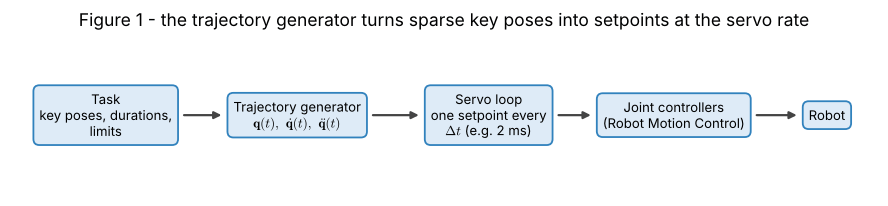

In [2]:
# Figure 1 - where the trajectory generator sits in the control chain
fig, ax = plt.subplots(figsize=(11.2, 2.1))
labels = ["Task\nkey poses, durations,\nlimits", "Trajectory generator\n" + r"$\mathbf{q}(t),\ \dot{\mathbf{q}}(t),\ \ddot{\mathbf{q}}(t)$",
          "Servo loop\none setpoint every\n" + r"$\Delta t$ (e.g. 2 ms)", "Joint controllers\n(Robot Motion Control)", "Robot"]
xs = [0.9, 3.9, 6.9, 9.8, 12.2]
texts = [ax.text(x, 0.5, lab, ha="center", va="center", fontsize=9.5,
                 bbox=dict(boxstyle="round,pad=0.45", fc="#deebf7", ec="#3182bd", lw=1.3)) for x, lab in zip(xs, labels)]
ax.set_xlim(-0.6, 13.0); ax.set_ylim(0, 1); ax.set_axis_off()
fig.canvas.draw()
inv = ax.transData.inverted()
ext = [inv.transform(tx.get_bbox_patch().get_window_extent()) for tx in texts]          # box corners in data coordinates
for e0, e1 in zip(ext[:-1], ext[1:]):
    ax.annotate("", xy=(e1[0, 0] - 0.05, 0.5), xytext=(e0[1, 0] + 0.05, 0.5), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#444"))
ax.set_title("Figure 1 - the trajectory generator turns sparse key poses into setpoints at the servo rate")
plt.show()

## 2. What makes a trajectory acceptable

Every trajectory must pass through the specified key poses at the specified times. Beyond that, a *good*
trajectory satisfies requirements that come from physics. Think of $\boldsymbol q(t)$ as a function whose
successive derivatives are each tied to something the hardware can or cannot do.

| Derivative | If it is **discontinuous** … | Consequence |
|:--|:--|:--|
| position $q$ | the robot would have to teleport | impossible; always continuous |
| velocity $\dot q$ | the acceleration is infinite for an instant | an unbounded torque is demanded; in practice a shock, saturation, large tracking error |
| acceleration $\ddot q$ | the required torque jumps (Chapter 6: $\boldsymbol\tau = M\ddot{\boldsymbol q}+\cdots$) | excites gear backlash and link flexibility; audible knock and residual vibration |
| jerk $\dddot q$ | the *rate of change* of torque is unbounded | accelerated wear; vibration of lightly damped modes; the reason CNC machines use "S-curves" |

Two further requirements are about size rather than smoothness. The velocity and acceleration must stay within
the **limits** of the joints, which are set by the motor speed, the available torque and the payload; and, unless
told otherwise, a point-to-point move should **start and end at rest**, so that consecutive moves can be chained
without a jump.

**Linear interpolation does not meet these requirements.** The simplest idea is the straight line
$q(t) = q_0 + (q_f - q_0)\,t/T$. Its velocity is constant, $\Delta/T$, but the robot is at rest before $t=0$:
the velocity jumps from $0$ to $\Delta/T$ in zero time, and the acceleration is a Dirac impulse. A servo loop that
samples the setpoint every $\Delta t$ sees this impulse as a spike of height $\Delta/(T\,\Delta t)$ in the
second difference — and the spike grows without bound as the sampling is made finer. Figure 2 shows it.

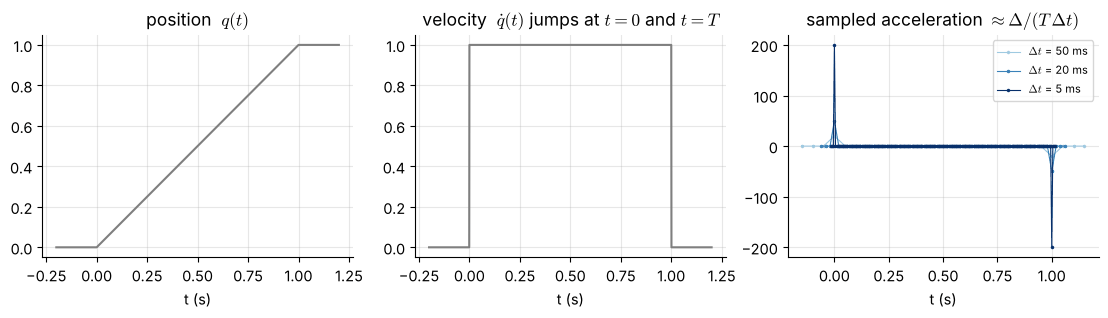

dt =  50.0 ms   peak sampled acceleration =     20.0   predicted D/(T dt) =     20.0
dt =  20.0 ms   peak sampled acceleration =     50.0   predicted D/(T dt) =     50.0
dt =   5.0 ms   peak sampled acceleration =    200.0   predicted D/(T dt) =    200.0


In [3]:
# Figure 2 - linear interpolation: finite acceleration estimates grow like 1/dt
D, T = 1.0, 1.0
lin = tj.linear(0.0, D, T)
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.3))
t = np.linspace(-0.2, 1.2, 1401)
axes[0].plot(t, lin.pos(t), color=PAL["linear"]); axes[0].set_title("position  $q(t)$")
axes[1].plot(t, lin.vel(t), color=PAL["linear"]); axes[1].set_title(r"velocity  $\dot q(t)$ jumps at $t=0$ and $t=T$")
rows = []
for dt, col in [(0.05, "#9ecae1"), (0.02, "#3182bd"), (0.005, "#08306b")]:
    k = np.arange(-4, int(round(T / dt)) + 5)
    ts = k * dt
    q = lin.pos(ts)
    acc = (q[2:] - 2 * q[1:-1] + q[:-2]) / dt ** 2          # second difference of the sampled setpoints
    axes[2].plot(ts[1:-1], acc, ".-", color=col, ms=3, lw=0.8, label=f"$\\Delta t$ = {dt*1000:g} ms")
    rows.append((dt, np.abs(acc).max(), D / (T * dt)))
axes[2].set_title(r"sampled acceleration $\approx \Delta/(T\,\Delta t)$"); axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("t (s)")
plt.tight_layout(); plt.show()
for dt, peak, pred in rows:
    print(f"dt = {dt*1000:5.1f} ms   peak sampled acceleration = {peak:8.1f}   predicted D/(T dt) = {pred:8.1f}")
    assert np.isclose(peak, pred)

The cure is to give the trajectory more freedom: make $q(t)$ a polynomial of high enough degree that the
derivatives we care about can be forced to match at both ends. The next sections do this systematically.

## 3. The cubic polynomial

Consider one joint that must go from $q_0$ at $t=0$ to $q_f$ at $t=T$, leaving with velocity $v_0$ and arriving with
velocity $v_f$ (both are zero for a move from rest to rest). Four conditions,

$$
q(0)=q_0,\qquad \dot q(0)=v_0,\qquad q(T)=q_f,\qquad \dot q(T)=v_f ,
$$

fix four free numbers, so we seek a cubic

$$
q(t) = a_0 + a_1 t + a_2 t^2 + a_3 t^3,\qquad
\dot q(t) = a_1 + 2a_2 t + 3a_3 t^2,\qquad
\ddot q(t) = 2a_2 + 6a_3 t .
$$

Substituting the four conditions gives a **linear system** for the coefficients,

$$
\begin{bmatrix} 1 & 0 & 0 & 0\\ 0 & 1 & 0 & 0\\ 1 & T & T^2 & T^3\\ 0 & 1 & 2T & 3T^2\end{bmatrix}
\begin{bmatrix} a_0\\ a_1\\ a_2\\ a_3\end{bmatrix}
=
\begin{bmatrix} q_0\\ v_0\\ q_f\\ v_f\end{bmatrix},
$$

whose first two rows give $a_0 = q_0$ and $a_1 = v_0$ immediately. The matrix is invertible for every $T>0$, so the
cubic exists and is unique. We let SymPy solve it for symbolic data, then confirm that the numerical routine
`rgkit.trajectory.cubic` returns the same coefficients.

In [4]:
t, T = sp.symbols("t T", positive=True)
q0, qf, v0, vf, D = sp.symbols("q_0 q_f v_0 v_f Delta", real=True)
a = sp.symbols("a_0:4")
q = sum(a[k] * t**k for k in range(4))
conds = [q.subs(t, 0) - q0, sp.diff(q, t).subs(t, 0) - v0, q.subs(t, T) - qf, sp.diff(q, t).subs(t, T) - vf]
A, b = sp.linear_eq_to_matrix(conds, a)
display(Math(sp.latex(A) + sp.latex(sp.Matrix(a)) + "=" + sp.latex(b)))
sol = sp.solve(conds, a, dict=True)[0]
for k in (2, 3):
    display(Math(rf"a_{k} = " + sp.latex(sp.simplify(sol[a[k]]))))

# numerical cross-check against the library routine (arbitrary data)
vals = {q0: 0.5, qf: 1.4, v0: 0.3, vf: -0.2, T: 1.5}
c_sym = [float(sol[a[k]].subs(vals)) for k in range(4)]
c_num = tj.cubic(0.5, 1.4, 1.5, v0=0.3, vf=-0.2).segment_coeffs(0)[0]
print("symbolic :", np.round(c_sym, 6))
print("numerical:", np.round(c_num, 6), "  agree:", np.allclose(c_sym, c_num))
assert np.allclose(c_sym, c_num)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

symbolic : [ 0.5     0.3     0.9333 -0.4889]
numerical: [ 0.5     0.3     0.9333 -0.4889]   agree: True


In Craig's form, with $\Delta = q_f - q_0$,

$$
a_0 = q_0,\qquad a_1 = v_0,\qquad
a_2 = \frac{3\Delta}{T^2} - \frac{2v_0 + v_f}{T},\qquad
a_3 = -\frac{2\Delta}{T^3} + \frac{v_0 + v_f}{T^2}.
$$

**Rest to rest.** With $v_0=v_f=0$ the coefficients collapse to $a_2 = 3\Delta/T^2$ and $a_3 = -2\Delta/T^3$, which is
conveniently written with the **normalised time** $\tau = t/T\in[0,1]$:

$$
q(t) = q_0 + \Delta\,\bigl(3\tau^2 - 2\tau^3\bigr),\qquad
\dot q = \frac{6\Delta}{T}\,\tau(1-\tau),\qquad
\ddot q = \frac{6\Delta}{T^2}\,(1-2\tau),\qquad
\dddot q = -\frac{12\Delta}{T^3}.
$$

Reading off the shape: the velocity is a parabola with its single maximum at the midpoint,
$\dot q_{\max} = \tfrac32\,\Delta/T$ (one and a half times the average speed $\Delta/T$); the acceleration falls
linearly from $+6\Delta/T^2$ to $-6\Delta/T^2$; the jerk is constant. Note what the cubic does **not** do: the
acceleration is *not* zero at the ends, so it jumps from $0$ to $6\Delta/T^2$ at the start of the motion and from
$-6\Delta/T^2$ to $0$ at its end. The cubic is continuous in position and velocity ($C^1$) but not in acceleration.

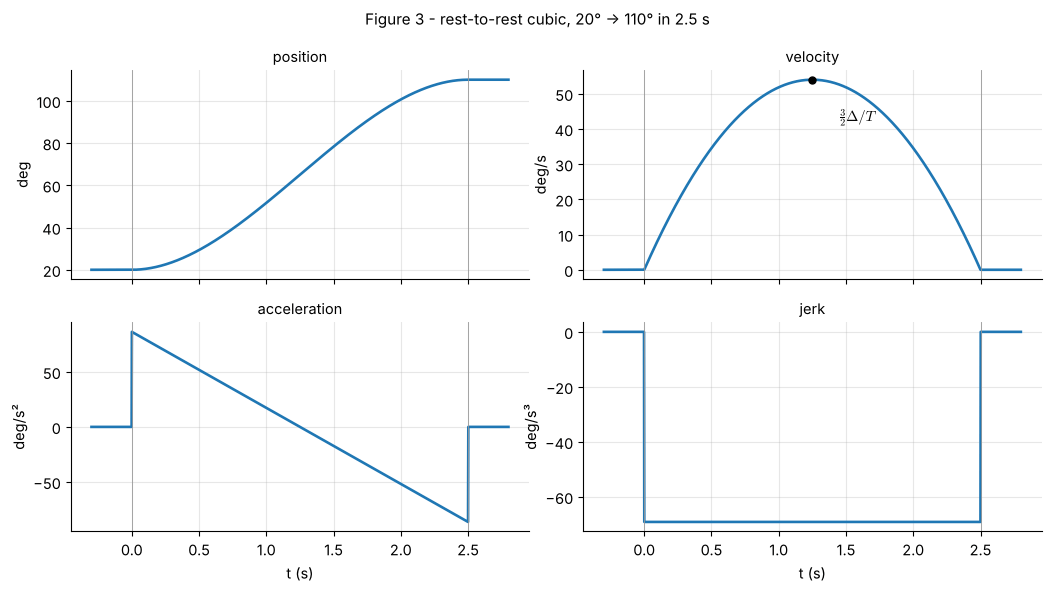

peak velocity 54.00 deg/s (3/2 Δ/T = 54.00);  peak |acceleration| 86.40 deg/s² (6Δ/T² = 86.40)


In [5]:
def profile_panels(items, T, figsize=(10.4, 6.0), pad=0.12, title=None, units=("q", r"$\dot q$", r"$\ddot q$", r"$\dddot q$")):
    """Plot position, velocity, acceleration and jerk of several trajectories; items = [(label, traj, colour), ...]."""
    fig, axs = plt.subplots(2, 2, figsize=figsize, sharex=True)
    t = np.linspace(-pad * T, (1 + pad) * T, 1601)
    for lab, tr, col in items:
        for ax, f in zip(axs.ravel(), (tr.pos, tr.vel, tr.acc, tr.jerk)):
            ax.plot(t, f(t), color=col, lw=1.9, label=lab)
    for ax, name in zip(axs.ravel(), ("position", "velocity", "acceleration", "jerk")):
        ax.set_title(name, fontsize=10.5); ax.axvline(0, color="#999", lw=0.6); ax.axvline(T, color="#999", lw=0.6)
    for ax in axs[1]:
        ax.set_xlabel("t (s)")
    if len(items) > 1:
        axs[0, 0].legend(fontsize=8.5, loc="best")
    if title:
        fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    return fig, axs

Delta, T = 90.0, 2.5                       # degrees, seconds (the numbers of Example 7.1.1)
cub = tj.cubic(20.0, 20.0 + Delta, T)
fig, axs = profile_panels([("cubic, rest to rest", cub, PAL["cubic"])], T, title="Figure 3 - rest-to-rest cubic, 20° → 110° in 2.5 s")
for ax, u in zip(axs.ravel(), ("deg", "deg/s", "deg/s²", "deg/s³")):
    ax.set_ylabel(u)
tt = np.linspace(0, T, 5001)
axs[0, 1].plot(T / 2, 1.5 * Delta / T, "ko", ms=5); axs[0, 1].annotate(r"$\frac{3}{2}\Delta/T$", (T / 2, 1.5 * Delta / T), (T / 2 + 0.2, 1.5 * Delta / T - 12))
plt.show()
print(f"peak velocity {cub.vel(tt).max():.2f} deg/s (3/2 Δ/T = {1.5*Delta/T:.2f});  peak |acceleration| {np.abs(cub.acc(tt)).max():.2f} deg/s² (6Δ/T² = {6*Delta/T**2:.2f})")

## 4. The quintic polynomial

To remove the acceleration jump, impose two more conditions — the acceleration at both ends, usually
$\ddot q(0)=\ddot q(T)=0$ — and add two more coefficients:

$$
q(t)=a_0+a_1t+a_2t^2+a_3t^3+a_4t^4+a_5t^5 ,
\qquad
q(0)=q_0,\ \dot q(0)=v_0,\ \ddot q(0)=\alpha_0,\ \ q(T)=q_f,\ \dot q(T)=v_f,\ \ddot q(T)=\alpha_f .
$$

The six conditions give a $6\times6$ linear system. As before the first three coefficients are immediate,
$a_0 = q_0$, $a_1 = v_0$, $a_2 = \alpha_0/2$, and the remaining three come from the conditions at $t=T$.

In [6]:
t, T = sp.symbols("t T", positive=True)                                  # (T was a number in the previous cells)
c = sp.symbols("c_0:6")
q5 = sum(c[k] * t**k for k in range(6))
al0, alf = sp.symbols("alpha_0 alpha_f", real=True)
conds5 = [q5.subs(t, 0) - q0, sp.diff(q5, t).subs(t, 0) - v0, sp.diff(q5, t, 2).subs(t, 0) - al0,
          q5.subs(t, T) - qf, sp.diff(q5, t).subs(t, T) - vf, sp.diff(q5, t, 2).subs(t, T) - alf]
A5, b5 = sp.linear_eq_to_matrix(conds5, c)
display(Math(sp.latex(A5) + sp.latex(sp.Matrix(c)) + "=" + sp.latex(b5)))

sol5 = sp.solve(conds5, c, dict=True)[0]
rest = {v0: 0, vf: 0, al0: 0, alf: 0, qf: q0 + D}                          # rest to rest, zero end accelerations
for k in (3, 4, 5):
    display(Math(rf"c_{k} = " + sp.latex(sp.simplify(sol5[c[k]].subs(rest)))))

# peaks of the rest-to-rest quintic, found symbolically
q5r = sp.simplify(q5.subs(sol5).subs(rest))
vel5, acc5, jerk5 = [sp.diff(q5r, t, k) for k in (1, 2, 3)]
t_v = sp.solve(sp.diff(vel5, t), t)                                         # where velocity is stationary
t_a = sp.solve(sp.diff(acc5, t), t)                                         # where acceleration is stationary
print("velocity peak at t =", t_v, " value", sp.simplify(vel5.subs(t, t_v[0])))
print("acceleration extrema at t =", [sp.simplify(x) for x in t_a], " values", [sp.simplify(acc5.subs(t, x)) for x in t_a])
print("jerk at t=0:", sp.simplify(jerk5.subs(t, 0)), "   jerk at t=T/2:", sp.simplify(jerk5.subs(t, T / 2)))

# the same numbers from the library (Delta = 1, T = 1)
qn = tj.quintic(0.0, 1.0, 1.0); tt = np.linspace(0, 1, 20001)
print("library: v_max =", qn.vel(tt).max().round(6), "  15/8 =", 15 / 8,
      "|  a_max =", np.abs(qn.acc(tt)).max().round(6), "  10/sqrt(3) =", round(10 / np.sqrt(3), 6),
      "|  jerk_max =", np.abs(qn.jerk(tt)).max().round(6))
assert np.isclose(qn.vel(tt).max(), 15 / 8, atol=1e-6) and np.isclose(np.abs(qn.acc(tt)).max(), 10 / np.sqrt(3), atol=1e-6)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

velocity peak at t = [T/2, T]  value 15*Delta/(8*T)
acceleration extrema at t = [T*(3 - sqrt(3))/6, T*(sqrt(3) + 3)/6]  values [10*sqrt(3)*Delta/(3*T**2), -10*sqrt(3)*Delta/(3*T**2)]
jerk at t=0: 60*Delta/T**3    jerk at t=T/2: -30*Delta/T**3
library: v_max = 1.875   15/8 = 1.875 |  a_max = 5.773503   10/sqrt(3) = 5.773503 |  jerk_max = 60.0


In normalised time the rest-to-rest quintic is

$$
q(t) = q_0 + \Delta\,\bigl(10\tau^3 - 15\tau^4 + 6\tau^5\bigr),\qquad
\dot q = \frac{30\Delta}{T}\,\tau^2(1-\tau)^2,\qquad
\ddot q = \frac{60\Delta}{T^2}\,\tau(1-\tau)(1-2\tau),\qquad
\dddot q = \frac{60\Delta}{T^3}\,\bigl(1-6\tau+6\tau^2\bigr).
$$

Its peak velocity is $\dot q(T/2) = \tfrac{15}{8}\,\Delta/T = 1.875\,\Delta/T$; the extrema of the acceleration
are $\pm\tfrac{10}{\sqrt3}\,\Delta/T^2 \approx \pm5.774\,\Delta/T^2$ at $\tau=(3\mp\sqrt3)/6$; and the jerk jumps from $0$ to
$60\Delta/T^3$ at the start. The quintic is continuous in position, velocity **and acceleration** ($C^2$): the
torque no longer steps at the start and the end. Figure 4 compares it with the cubic and with the straight line
for the same move.

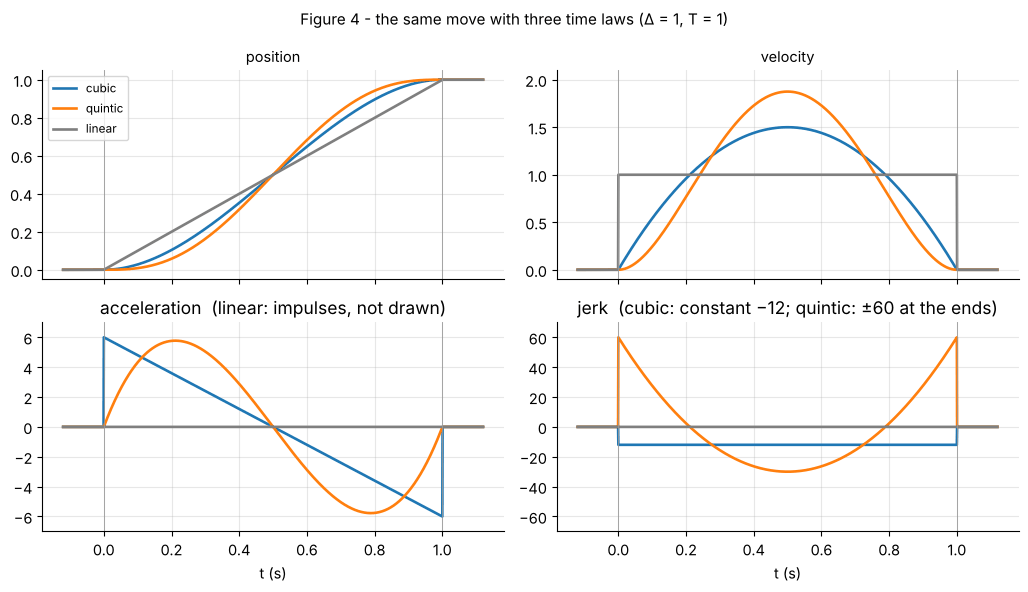

In [7]:
# Figure 4 - linear, cubic and quintic for the same normalised move (Delta = 1, T = 1)
items = [("cubic", tj.cubic(0.0, 1.0, 1.0), PAL["cubic"]), ("quintic", tj.quintic(0.0, 1.0, 1.0), PAL["quintic"]),
         ("linear", tj.linear(0.0, 1.0, 1.0), PAL["linear"])]
fig, axs = profile_panels(items, 1.0, title="Figure 4 - the same move with three time laws (Δ = 1, T = 1)")
axs[0, 1].set_ylim(-0.1, 2.1); axs[1, 0].set_ylim(-7, 7); axs[1, 1].set_ylim(-70, 70)
axs[1, 0].set_title("acceleration  (linear: impulses, not drawn)"); axs[1, 1].set_title("jerk  (cubic: constant −12; quintic: ±60 at the ends)")
plt.show()

**Animation.** The top panel of the animation below shows three carts travelling along a rail from $0$ to $1$
in the same time with the three laws; the bottom panel shows their velocities. The linear cart leaps to full speed
instantly; the cubic and quintic carts accelerate gradually, and the quintic leaves and arrives more gently
(zero acceleration) but passes the middle faster.

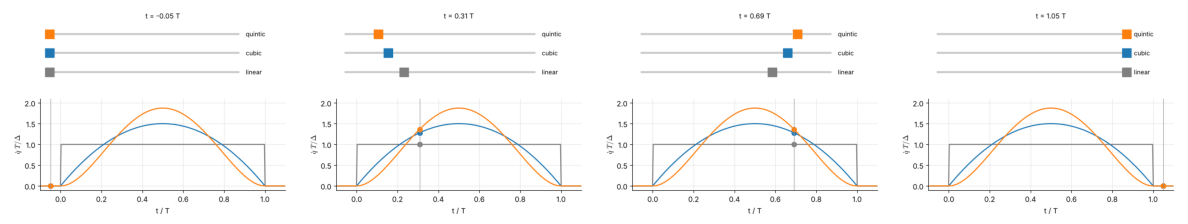

In [8]:
laws = [("linear", tj.linear(0.0, 1.0, 1.0), PAL["linear"]), ("cubic", tj.cubic(0.0, 1.0, 1.0), PAL["cubic"]),
        ("quintic", tj.quintic(0.0, 1.0, 1.0), PAL["quintic"])]
fig, (ax_rail, ax_v) = plt.subplots(2, 1, figsize=(6.4, 4.4), gridspec_kw=dict(height_ratios=[1, 1.5]))
tv = np.linspace(-0.1, 1.1, 400)

def update(tc):
    ax_rail.cla(); ax_v.cla()
    for k, (lab, tr, col) in enumerate(laws):
        ax_rail.plot([0, 1], [k, k], color="#ccc", lw=3, zorder=1)
        ax_rail.plot(tr.pos(tc), k, "s", color=col, ms=13, zorder=3)
        ax_rail.text(1.04, k, lab, va="center", fontsize=9)
        ax_v.plot(tv, tr.vel(tv), color=col, lw=1.6)
        ax_v.plot(tc, tr.vel(tc), "o", color=col, ms=7)
    ax_rail.set_xlim(-0.05, 1.25); ax_rail.set_ylim(-0.6, 2.6); ax_rail.set_axis_off()
    ax_rail.set_title(f"t = {tc:4.2f} T", fontsize=10)
    ax_v.axvline(tc, color="#999", lw=0.8); ax_v.set_xlim(-0.1, 1.1); ax_v.set_ylim(-0.1, 2.1)
    ax_v.set_xlabel("t / T"); ax_v.set_ylabel(r"$\dot q\; T/\Delta$")

animate(fig, update, np.linspace(-0.05, 1.05, 44), interval=80, gif="assets/7.1-polynomial-time-laws.gif",
        keyframe_titles=None)

## 5. The general rule: smoother start and stop, higher peaks

The pattern is now clear. If we want the first $m-1$ derivatives to be prescribed at both ends, there are $2m$
conditions and the interpolating polynomial has degree $2m-1$ (so $m=2$: cubic, $m=3$: quintic, $m=4$: septic of
degree 7). This is **Hermite interpolation**. The coefficient system keeps the same shape: the first $m$
coefficients are $a_k = q^{(k)}(0)/k!$ and the other $m$ come from one $m\times m$ system, which is what
`rgkit.trajectory.hermite_coeffs` solves.

The price of smoothness is visible in the normalised peaks of the rest-to-rest polynomials (all with
$\Delta = T = 1$): demanding more zero derivatives at the ends squeezes the motion into the middle of the
interval, so the **peak velocity and peak acceleration rise** even though the average speed is fixed at
$\Delta/T$.

| Polynomial | degree | peak $\dot q$ | peak $\lvert\ddot q\rvert$ | peak $\lvert\dddot q\rvert$ | peak $\lvert q^{(4)}\rvert$ |
|:--|--:|--:|--:|--:|--:|
| linear (m=1) | 1 | 1 | ∞ (impulse) | ∞ (impulse) | ∞ (impulse) |
| cubic (m=2) | 3 | 1.5 | 6 | 12 | 0 |
| quintic (m=3) | 5 | 1.875 | 5.774 | 60 | 360 |
| septic (m=4) | 7 | 2.187 | 7.513 | 52.5 | 840 |
| degree 9 (m=5) | 9 | 2.461 | 9.372 | 78.75 | 622.5 |


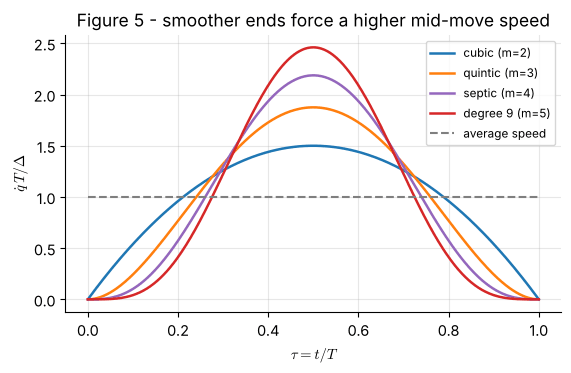

In [9]:
names = {1: "linear (m=1)", 2: "cubic (m=2)", 3: "quintic (m=3)", 4: "septic (m=4)", 5: "degree 9 (m=5)"}
tt = np.linspace(0, 1, 40001)
rows, profiles = [], {}
for m in range(1, 6):
    start = np.zeros(m); end = np.zeros(m); end[0] = 1.0                          # rest to rest: q: 0 -> 1, higher derivatives 0
    c = tj.hermite_coeffs(1.0, start, end)
    P = np.polynomial.Polynomial(c)
    profiles[m] = P
    peaks = [np.abs(P.deriv(k)(tt)).max() for k in (1, 2, 3, 4)]
    rows.append((names[m], 2 * m - 1, *peaks))
tbl = "| Polynomial | degree | peak $\\dot q$ | peak $\\lvert\\ddot q\\rvert$ | peak $\\lvert\\dddot q\\rvert$ | peak $\\lvert q^{(4)}\\rvert$ |\n|:--|--:|--:|--:|--:|--:|\n"
for name, deg_, v_, a_, j_, s_ in rows:
    fmt = lambda x, kind: ("∞ (impulse)" if (name.startswith("linear") and kind >= 2) else f"{x:.4g}")
    tbl += f"| {name} | {deg_} | {fmt(v_,1)} | {fmt(a_,2)} | {fmt(j_,3)} | {fmt(s_,4)} |\n"
display(Markdown(tbl))
assert np.isclose(rows[1][2], 1.5) and np.isclose(rows[2][2], 15 / 8) and np.isclose(rows[2][3], 10 / np.sqrt(3)) and np.isclose(rows[2][4], 60)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
tau = np.linspace(0, 1, 400)
for m, col in zip(range(2, 6), [PAL["cubic"], PAL["quintic"], PAL["septic"], PAL["other"]]):
    ax.plot(tau, profiles[m].deriv(1)(tau), color=col, lw=1.8, label=names[m])
ax.plot([0, 1], [1, 1], color=PAL["linear"], ls="--", label="average speed")
ax.set_xlabel(r"$\tau = t/T$"); ax.set_ylabel(r"$\dot q\,T/\Delta$"); ax.legend(fontsize=8.5)
ax.set_title("Figure 5 - smoother ends force a higher mid-move speed"); plt.show()

## 6. Why the quintic? A minimum-jerk property

Is the quintic merely convenient, or is it the *best* rest-to-rest polynomial in some sense? Take **jerk** as the
quantity to keep small — it measures how abruptly the torque changes — and ask for the function $q(t)$ that
satisfies the six end conditions and minimises the total squared jerk

$$
J[q] = \int_0^T \dddot q(t)^2\,dt .
$$

This is a problem in the calculus of variations. For a perturbation $q + \varepsilon p$ with $p$ vanishing, together
with $\dot p$ and $\ddot p$, at both ends (so the boundary conditions are preserved),

$$
J[q+\varepsilon p] = J[q] + 2\varepsilon\int_0^T \dddot q\,\dddot p\,dt + \varepsilon^2\int_0^T \dddot p^{\,2}dt ,
\qquad
\int_0^T \dddot q\,\dddot p\,dt = -\int_0^T q^{(6)}\,p\,dt \quad(\text{three integrations by parts}).
$$

The first-order term vanishes for every admissible $p$ exactly when $q^{(6)}\equiv 0$, i.e. when $q$ is a
polynomial of degree at most five; the second-order term is positive, so that polynomial is the *minimum*. The same
argument gives a ladder of results:

| Minimise | Euler–Lagrange equation | Optimal rest-to-rest function |
|:--|:--|:--|
| $\int \ddot q^2\,dt$ (acceleration energy) | $q^{(4)}=0$ | **cubic** |
| $\int \dddot q^2\,dt$ (jerk energy) | $q^{(6)}=0$ | **quintic** (the *minimum-jerk* trajectory) |
| $\int (q^{(4)})^2\,dt$ | $q^{(8)}=0$ | septic |

The optimal costs for $\Delta=T=1$ are $12$ for the cubic ($\int\ddot q^2$) and $720$ for the quintic
($\int\dddot q^2$). The cell below confirms both by brute force: adding admissible perturbations can only
increase the cost, and the cost is a parabola in $\varepsilon$ with its minimum at $\varepsilon=0$. Minimum-jerk
trajectories are also a good model of human reaching movements, which is one reason they feel natural.

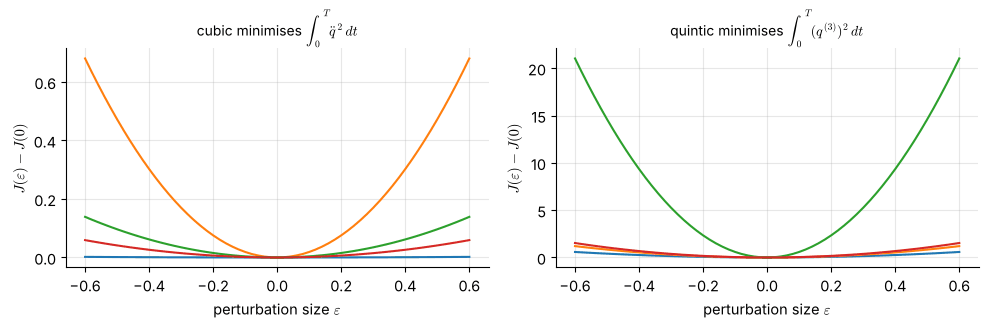

optimal costs (Δ = T = 1):  cubic, integral of acceleration² = 12;  quintic, integral of jerk² = 720


In [10]:
from numpy.polynomial import Polynomial as Poly
rng = np.random.default_rng(7)
tt = np.linspace(0, 1, 6001)
Pc, Pq = Poly(tj.cubic(0.0, 1.0, 1.0).segment_coeffs(0)[0]), Poly(tj.quintic(0.0, 1.0, 1.0).segment_coeffs(0)[0])
bump = lambda order: (Poly([0, 1]) * Poly([1, -1])) ** order          # (t(1-t))^order: vanishes with its first order-1 derivatives
eps = np.linspace(-0.6, 0.6, 61)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, base, order, deriv, name, J0 in [(axes[0], Pc, 2, 2, r"cubic minimises $\int_0^T \ddot{q}^{\,2}\,dt$", 12.0),
                                          (axes[1], Pq, 3, 3, r"quintic minimises $\int_0^T (q^{(3)})^{2}\,dt$", 720.0)]:
    Jb = np.trapezoid(base.deriv(deriv)(tt) ** 2, tt)
    assert np.isclose(Jb, J0, rtol=1e-6)
    for _ in range(4):
        p = bump(order) * Poly(rng.normal(size=3))
        J = [np.trapezoid((base + e * p).deriv(deriv)(tt) ** 2, tt) for e in eps]
        assert min(J) >= Jb - 1e-6 and np.isclose(J[30], Jb)               # eps = 0 is the minimum
        ax.plot(eps, np.array(J) - Jb, lw=1.5)
    ax.set_xlabel(r"perturbation size $\varepsilon$"); ax.set_ylabel(r"$J(\varepsilon) - J(0)$"); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()
print("optimal costs (Δ = T = 1):  cubic, integral of acceleration² = 12;  quintic, integral of jerk² = 720")

## 7. Scaling laws and the minimum duration

All the closed forms above have the structure $q(t) = q_0 + \Delta\,\varphi(t/T)$ with a fixed **normalised
profile** $\varphi$ (for instance $3\tau^2-2\tau^3$). Differentiating with respect to $t$ pulls out one factor
$1/T$ per derivative:

$$
\dot q_{\max} = c_v\,\frac{|\Delta|}{T},\qquad
\ddot q_{\max} = c_a\,\frac{|\Delta|}{T^2},\qquad
\dddot q_{\max} = c_j\,\frac{|\Delta|}{T^3},
$$

where $(c_v, c_a, c_j)$ are pure numbers of the profile: $(1.5,\ 6,\ 12)$ for the cubic and
$(1.875,\ 5.774,\ 60)$ for the quintic. **Doubling the duration halves the peak velocity, quarters the peak
acceleration and divides the peak jerk by eight.** Time is therefore the lever by which a trajectory is made to
respect the actuator limits: if the joint may not exceed $v_{\max}$ and $a_{\max}$ we need

$$
T \;\ge\; \max\!\Bigl(\frac{c_v|\Delta|}{v_{\max}},\ \sqrt{\frac{c_a|\Delta|}{a_{\max}}}\Bigr)
\qquad\Bigl(\text{and } T\ge\sqrt[3]{c_j|\Delta|/j_{\max}}\text{ if the jerk is limited}\Bigr).
$$

Figure 6 plots the peaks against $T$ for the move of Example 7.1.4 ($\Delta = 1.2$ rad,
$v_{\max}=1$ rad/s, $a_{\max}=2.5$ rad/s²): the minimum duration is where each curve first dips below its limit.
For this move the cubic is limited by velocity, $T_{\min}=1.8$ s, and the quintic also by velocity,
$T_{\min}=2.25$ s — the price of the extra smoothness.

minimum durations: {'cubic': 1.8, 'quintic': 2.25}


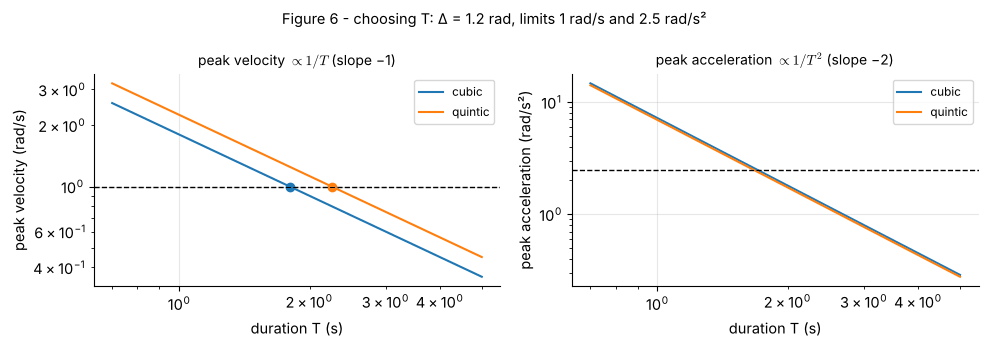

In [11]:
Dl, vlim, alim = 1.2, 1.0, 2.5
coef = {"cubic": (1.5, 6.0), "quintic": (15 / 8, 10 / np.sqrt(3))}
Tmin = {k: max(cv * Dl / vlim, np.sqrt(ca * Dl / alim)) for k, (cv, ca) in coef.items()}
print("minimum durations:", {k: round(v, 3) for k, v in Tmin.items()})
assert np.isclose(Tmin["cubic"], 1.8) and np.isclose(Tmin["quintic"], 2.25)

# check by brute force on the actual trajectories
for k, f in (("cubic", tj.cubic), ("quintic", tj.quintic)):
    for Tt, ok in ((Tmin[k] * 0.999, False), (Tmin[k] * 1.001, True)):
        rep = tj.check_limits(f(0.0, Dl, Tt), v_lim=vlim, a_lim=alim)
        assert rep["ok"] == ok

Ts = np.logspace(np.log10(0.7), np.log10(5), 80)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for k, col in (("cubic", PAL["cubic"]), ("quintic", PAL["quintic"])):
    cv, ca = coef[k]
    axes[0].loglog(Ts, cv * Dl / Ts, color=col, label=k); axes[1].loglog(Ts, ca * Dl / Ts ** 2, color=col, label=k)
    axes[0].plot(Tmin[k], cv * Dl / Tmin[k], "o", color=col)
axes[0].axhline(vlim, color="k", ls="--", lw=1); axes[1].axhline(alim, color="k", ls="--", lw=1)
axes[0].set_ylabel("peak velocity (rad/s)"); axes[1].set_ylabel("peak acceleration (rad/s²)")
for ax, ttl in zip(axes, ("peak velocity $\\propto 1/T$ (slope −1)", "peak acceleration $\\propto 1/T^2$ (slope −2)")):
    ax.set_xlabel("duration T (s)"); ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8.5)
plt.suptitle("Figure 6 - choosing T: Δ = 1.2 rad, limits 1 rad/s and 2.5 rad/s²", fontsize=10.5); plt.tight_layout(); plt.show()

**Interactive explorer.** Change the duration, the move size and the end velocities and watch the four curves.
Notice how a non-zero end velocity changes the *shape*, not just the peaks, and how for the cubic the
acceleration jumps at the ends whereas for the quintic and septic it does not (the septic also has zero jerk
at the ends).

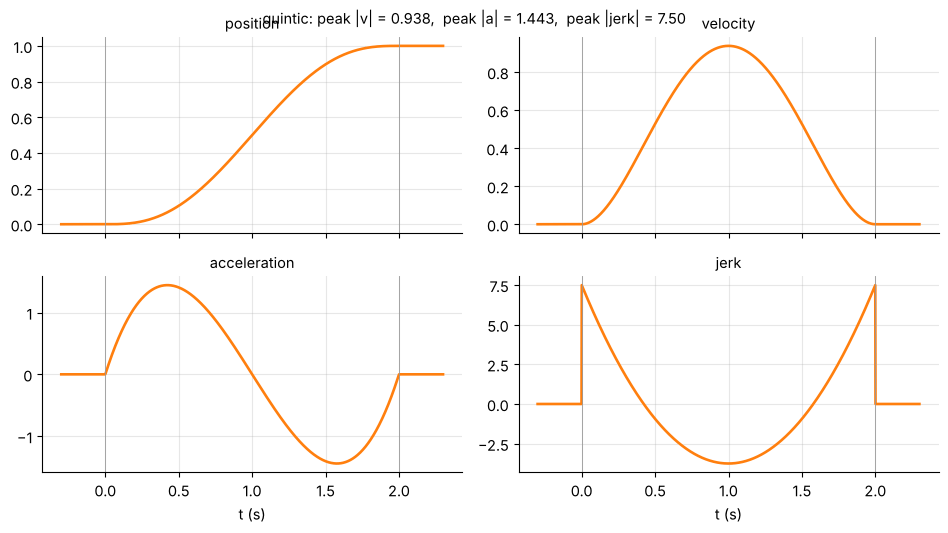

In [12]:
def explore(kind="quintic", T=2.0, delta=1.0, v0=0.0, vf=0.0):
    f = dict(cubic=lambda: tj.cubic(0.0, delta, T, v0, vf), quintic=lambda: tj.quintic(0.0, delta, T, v0, vf),
             septic=lambda: tj.septic(0.0, delta, T, v0, vf))[kind]
    tr = f()
    fig, axs = profile_panels([(kind, tr, PAL[kind])], T, figsize=(9.6, 5.4), pad=0.15)
    tt = np.linspace(0, T, 2001)
    fig.suptitle(f"{kind}: peak |v| = {np.abs(tr.vel(tt)).max():.3f},  peak |a| = {np.abs(tr.acc(tt)).max():.3f},  "
                 f"peak |jerk| = {np.abs(tr.jerk(tt)).max():.2f}", fontsize=10.5)
    plt.show()

interact(explore, kind=widgets.Dropdown(options=["cubic", "quintic", "septic"], value="quintic", description="polynomial"),
         T=widgets.FloatSlider(min=0.5, max=5.0, step=0.1, value=2.0, description="T (s)"),
         delta=widgets.FloatSlider(min=-2.0, max=2.0, step=0.1, value=1.0, description="Δ (rad)"),
         v0=widgets.FloatSlider(min=-1.5, max=1.5, step=0.1, value=0.0, description="v0"),
         vf=widgets.FloatSlider(min=-1.5, max=1.5, step=0.1, value=0.0, description="vf"));

## 8. Several joints at once

A six-joint arm needs six trajectories. The simplest coordinated scheme gives **every joint the same duration
$T$** and computes each polynomial independently from its own $q_{i,0}$ and $q_{i,f}$. All joints then leave and
arrive together. Three consequences are worth stating.

1. **The slowest joint decides $T$.** Each joint $i$ imposes its own minimum duration $T_i$ from
   Section 7 (it has its own $\Delta_i$ and its own limits $v_i^{\max}$, $a_i^{\max}$); the common duration is
   $T=\max_i T_i$. Joints that could go faster simply move more gently.
2. **Every joint follows the same normalised profile.** With rest-to-rest conditions,
   $\boldsymbol q(t) = \boldsymbol q_0 + \varphi(t/T)\,(\boldsymbol q_f-\boldsymbol q_0)$. In joint space the point moves along the
   **straight line** from $\boldsymbol q_0$ to $\boldsymbol q_f$, with a scalar time law $s=\varphi(t/T)$. (This is the
   first appearance of the split $\boldsymbol q(t) = \boldsymbol q(s(t))$ of Section 1.)
3. **A straight line in joint space is not a straight line in the world.** The kinematics are nonlinear, so the
   tool follows a curve whose shape and speed profile depend on the arm — the topic of the next section and
   of Notebook 7.4.

## 9. A real robot: a UR5e quintic in joint space

We now execute these ideas on the **Universal Robots UR5e**, a six-joint industrial arm, loaded from MuJoCo
Menagerie (see [docs/MUJOCO.md](../../docs/MUJOCO.md); the model is downloaded on first use). The move goes from
the manufacturer's *home* configuration $\boldsymbol q_A$ to another configuration $\boldsymbol q_B$ in
$T = 2$ s along a rest-to-rest quintic. In this notebook we only **play the trajectory back kinematically**
(set the joint angles, ask MuJoCo for the forward kinematics); Notebook 7.5 sends the same setpoints through the
simulator's actuators and studies how well the arm tracks them.

Three checks make the playback trustworthy: the six joint curves obey the joint ranges stored in the model; the
tool velocity computed from the Jacobian, $\dot{\boldsymbol p} = J(\boldsymbol q)\,\dot{\boldsymbol q}$ (MuJoCo's `mj_jacSite`),
agrees with the numerical derivative of the tool position; and the tool path is *not* the straight chord between
its end points.

In [13]:
from rgkit import mujoco_utils as mju, robots
import mujoco
print(robots.describe("ur5e"))
model, data = robots.load_robot("ur5e")
site = model.site("attachment_site").id
qA = np.array(model.key_qpos[0])                                  # the manufacturer's home keyframe
qB = np.array([0.40, -1.20, 1.60, -1.90, -1.20, 0.80])
T_move = 2.0
traj = tj.quintic(qA, qB, T_move)

def tool_pos(q):
    data.qpos[:] = q; mujoco.mj_kinematics(model, data)
    return data.site_xpos[site].copy()

ts = np.linspace(0, T_move, 201)
Q, Qd = traj.pos(ts), traj.vel(ts)
P = np.array([tool_pos(q) for q in Q])
jacp, jacr = np.zeros((3, model.nv)), np.zeros((3, model.nv))
Pdot_J = []
for q, qd in zip(Q, Qd):
    data.qpos[:] = q; mujoco.mj_forward(model, data)
    mujoco.mj_jacSite(model, data, jacp, jacr, site)
    Pdot_J.append(jacp @ qd)
Pdot_J = np.array(Pdot_J)
Pdot_fd = np.gradient(P, ts, axis=0)
err = np.abs(Pdot_J - Pdot_fd)[2:-2].max()
speed = np.linalg.norm(Pdot_J, axis=1)
print(f"tool at q_A: {P[0].round(3)} m,   tool at q_B: {P[-1].round(3)} m")
print(f"J(q) qdot vs finite difference of the tool position: max difference {err:.1e} m/s  (peak tool speed {speed.max():.3f} m/s)  ->", err < 5e-3)
assert err < 5e-3

chord = P[0] + (ts / T_move)[:, None] * (P[-1] - P[0])
dev = np.linalg.norm(P - chord, axis=1).max()
print(f"largest distance of the tool path from the straight chord: {dev*100:.1f} cm   (chord length {np.linalg.norm(P[-1]-P[0])*100:.1f} cm)")
lo, hi = model.jnt_range[:, 0], model.jnt_range[:, 1]
VLIM, ALIM = np.full(6, 3.0), np.full(6, 10.0)                   # illustrative limits chosen for this notebook, not the manufacturer's
rep = tj.check_limits(traj, q_lim=(lo, hi), v_lim=VLIM, a_lim=ALIM)
assert (np.minimum(Q - lo, hi - Q) > 0).all()
print("closest approach to a joint limit (rad):", np.minimum(Q - lo, hi - Q).min(axis=0).round(2))
print("peak |velocity| / limit:", rep["vel"].round(2), "  peak |acceleration| / limit:", rep["acc"].round(2), "  all within limits:", rep["ok"])

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


tool at q_A: [-0.134  0.492  0.488] m,   tool at q_B: [-0.494 -0.394  0.306] m
J(q) qdot vs finite difference of the tool position: max difference 1.4e-04 m/s  (peak tool speed 1.100 m/s)  -> True
largest distance of the tool path from the straight chord: 27.2 cm   (chord length 97.3 cm)
closest approach to a joint limit (rad): [4.71 4.71 1.54 4.38 4.71 5.48]
peak |velocity| / limit: [0.62 0.12 0.01 0.1  0.12 0.25]   peak |acceleration| / limit: [0.28 0.05 0.   0.05 0.05 0.12]   all within limits: True


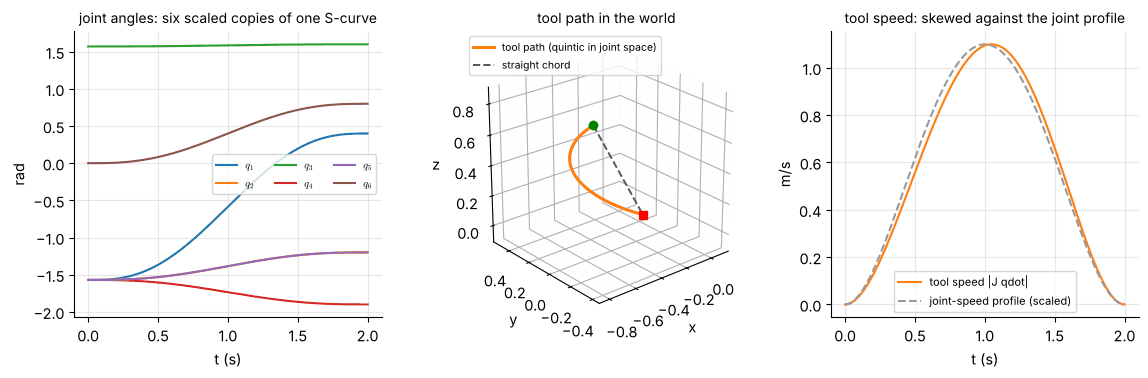

In [14]:
# Figure 7 - joint curves, tool path in space, tool speed
fig = plt.figure(figsize=(11.6, 3.9))
ax = fig.add_subplot(1, 3, 1)
for i in range(6):
    ax.plot(ts, Q[:, i], label=f"$q_{i+1}$")
ax.set_xlabel("t (s)"); ax.set_ylabel("rad"); ax.set_title("joint angles: six scaled copies of one S-curve", fontsize=10); ax.legend(ncol=3, fontsize=7.5)
ax3 = fig.add_subplot(1, 3, 2, projection="3d")
mid = (P.max(0) + P.min(0)) / 2; r = (P.max(0) - P.min(0)).max() / 2 * 1.15
new_axes3d(ax3, lim=[(m - r, m + r) for m in mid], elev=24, azim=-130)
ax3.plot(*P.T, color=PAL["quintic"], lw=2.2, label="tool path (quintic in joint space)")
ax3.plot(*np.array([P[0], P[-1]]).T, color="#555", ls="--", lw=1.4, label="straight chord")
ax3.plot(*P[0], "go"); ax3.plot(*P[-1], "rs"); ax3.legend(fontsize=7.5, loc="upper left"); ax3.set_title("tool path in the world", fontsize=10)
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(ts, speed, color=PAL["quintic"], label="tool speed |J qdot|")
ax2.plot(ts, np.abs(Qd).max(axis=1) * speed.max() / np.abs(Qd).max(), color="#999", ls="--", label="joint-speed profile (scaled)")
ax2.set_xlabel("t (s)"); ax2.set_ylabel("m/s"); ax2.set_title("tool speed: skewed against the joint profile", fontsize=10); ax2.legend(fontsize=8)
fig.tight_layout(); plt.show()

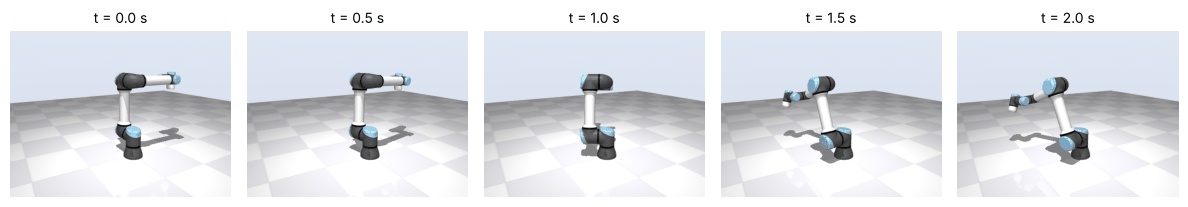

In [15]:
# Key frames of the move (kinematic playback)
frames, titles = [], []
cam = dict(azimuth=150, elevation=-14, distance=1.7, lookat=(-0.2, 0.0, 0.3))
for frac in (0.0, 0.25, 0.5, 0.75, 1.0):
    data.qpos[:] = traj.pos(frac * T_move); mujoco.mj_forward(model, data)
    frames.append(mju.render(model, data, camera=cam, width=440, height=330)); titles.append(f"t = {frac*T_move:.1f} s")
filmstrip(frames, titles)

Three observations deserve attention. First, the six joint curves are scaled copies of one S-shaped curve: they
start and stop together, exactly as Section 8 predicts. Second, the tool path bulges away from the chord between its
end points (the maximum separation is printed above): *the planner chose the straight line in the wrong space for a
tool that must travel in a line*. Third, the tool speed is not bell-shaped like the joint speeds — it depends on
the Jacobian, which changes along the motion. Both facts motivate the Cartesian-space schemes of Notebook 7.4.
Finally, a real controller would also verify the **joint limits**: the printed values show how close each
joint comes to its limit, and by what margin the (illustrative) velocity and acceleration limits are respected.

## 10. Worked examples

**Example 7.1.1 — a rest-to-rest cubic.** A joint at rest at $20^\circ$ must move smoothly to $110^\circ$ in
$T=2.5$ s. Find $a_2$, $a_3$, and the position, velocity and acceleration at $t=1$ s; find the peak velocity and
acceleration.

*Solution.* $\Delta = 90^\circ$, so $a_2 = 3\Delta/T^2 = 43.2\ \text{deg/s}^2$ and $a_3 = -2\Delta/T^3 = -11.52\ \text{deg/s}^3$.
Then $q(1) = 20 + 43.2 - 11.52 = 51.68^\circ$, $\dot q(1) = 2(43.2) + 3(-11.52) = 51.84$ deg/s and
$\ddot q(1) = 2(43.2) + 6(-11.52) = 17.28$ deg/s². The peak velocity is $\tfrac32\Delta/T = 54$ deg/s at $t = 1.25$ s;
the peak acceleration magnitude is $6\Delta/T^2 = 86.4$ deg/s², at $t=0$ and $t=T$.

**Example 7.1.2 — a cubic with end velocities.** A joint moves from $0.5$ rad to $1.4$ rad in $1.5$ s, leaving at
$0.3$ rad/s and arriving at $-0.2$ rad/s (it is about to reverse). Find the coefficients.

*Solution.* $\Delta=0.9$ rad. $a_0 = 0.5$, $a_1 = 0.3$,
$a_2 = 3\Delta/T^2 - (2v_0+v_f)/T = 1.2 - 0.4/1.5 = 0.9333$ rad/s², and
$a_3 = -2\Delta/T^3 + (v_0+v_f)/T^2 = -0.5333 + 0.0444 = -0.4889$ rad/s³. Check:
$\dot q(T) = 0.3 + 2(0.9333)(1.5) + 3(-0.4889)(2.25) = -0.2$ rad/s. ✓

**Example 7.1.3 — a rest-to-rest quintic.** A joint moves $0.8$ rad in $1.6$ s, from rest to rest with zero end
accelerations. Find the coefficients and the peak velocity, acceleration and jerk.

*Solution.* $a_3 = 10\Delta/T^3 = 1.953$, $a_4 = -15\Delta/T^4 = -1.831$, $a_5 = 6\Delta/T^5 = 0.4578$ (units
rad/s$^k$). Peak velocity $\tfrac{15}{8}\Delta/T = 0.9375$ rad/s at $t=0.8$ s; peak acceleration
$\tfrac{10}{\sqrt3}\Delta/T^2 = 1.804$ rad/s²; peak jerk $60\Delta/T^3 = 11.72$ rad/s³, reached at both ends.

**Example 7.1.4 — the shortest admissible duration.** A joint must move $1.2$ rad, rest to rest, with
$|\dot q|\le 1$ rad/s and $|\ddot q|\le 2.5$ rad/s². What are the shortest durations for a cubic and for a quintic?

*Solution.* Cubic: $T\ge \tfrac32(1.2)/1 = 1.8$ s from the velocity limit and $T\ge\sqrt{6(1.2)/2.5}=1.697$ s from the
acceleration limit, so $T_{\min} = 1.8$ s. Quintic: $T\ge\tfrac{15}{8}(1.2)/1 = 2.25$ s and
$T\ge\sqrt{(10/\sqrt3)(1.2)/2.5} = 1.665$ s, so $T_{\min}=2.25$ s. The velocity limit is binding in both cases.

**Example 7.1.5 — which joint sets the duration?** A six-joint move has $|\Delta| = (0.9,\ 1.6,\ 0.5,\ 2.1,\ 0.3,\ 1.2)$ rad,
all joints limited to $1.5$ rad/s and $6$ rad/s². Find the shortest common duration for a quintic.

*Solution.* Joint $i$ needs $T_i = \max\bigl(\tfrac{15}{8}|\Delta_i|/1.5,\ \sqrt{(10/\sqrt3)|\Delta_i|/6}\bigr)$. The largest move, joint 4 with
$2.1$ rad, gives $T_4 = 2.625$ s (velocity-limited) and is the binding joint; $T=2.625$ s works for all.

**Example 7.1.6 — questions about a cubic.** A cubic takes a joint from $10^\circ$ to $70^\circ$ in $4$ s, from
rest to rest. When is the acceleration zero, and what are $q$, $\dot q$, $\ddot q$ at $t=1$ s?

*Solution.* $a_2 = 3(60)/16 = 11.25$ deg/s² and $a_3 = -2(60)/64=-1.875$ deg/s³. The acceleration
$\ddot q = 22.5 - 11.25\,t$ vanishes at $t=2$ s, the midpoint, where the velocity peaks at $22.5$ deg/s.
At $t=1$: $q = 10 + 11.25 - 1.875 = 19.375^\circ$, $\dot q = 22.5 - 5.625 = 16.875$ deg/s, $\ddot q = 11.25$ deg/s².

In [16]:
# --- Example 7.1.1
c = tj.cubic(20.0, 110.0, 2.5); cf = c.segment_coeffs(0)[0]
assert np.allclose(cf, [20, 0, 43.2, -11.52])
print("7.1.1  a2, a3 =", cf[2], cf[3], "| q(1), qd(1), qdd(1) =", c.pos(1.0).round(3), c.vel(1.0).round(3), c.acc(1.0).round(3))
tt = np.linspace(0, 2.5, 100001)
assert np.isclose(c.pos(1.0), 51.68) and np.isclose(c.vel(1.0), 51.84) and np.isclose(c.acc(1.0), 17.28)
assert np.isclose(c.vel(tt).max(), 54.0) and np.isclose(tt[np.argmax(c.vel(tt))], 1.25) and np.isclose(np.abs(c.acc(tt)).max(), 86.4)

# --- Example 7.1.2
c2 = tj.cubic(0.5, 1.4, 1.5, v0=0.3, vf=-0.2); cf2 = c2.segment_coeffs(0)[0]
print("7.1.2  a2, a3 =", cf2[2].round(4), cf2[3].round(4), "| qd(T) =", c2.vel(1.5).round(4))
assert np.allclose([cf2[2], cf2[3]], [0.93333, -0.48889], atol=1e-4) and np.isclose(c2.vel(1.5), -0.2)

# --- Example 7.1.3
Dq, Tq = 0.8, 1.6
c3 = tj.quintic(0.0, Dq, Tq); cf3 = c3.segment_coeffs(0)[0]; tt = np.linspace(0, Tq, 100001)
print("7.1.3  a3, a4, a5 =", cf3[3:].round(4), "| v_max, a_max, jerk_max =", c3.vel(tt).max().round(4), np.abs(c3.acc(tt)).max().round(3), np.abs(c3.jerk(tt)).max().round(2))
assert np.allclose(cf3[3:], [1.953125, -1.8310547, 0.457764], atol=1e-5)
assert np.isclose(c3.vel(tt).max(), 0.9375) and np.isclose(np.abs(c3.acc(tt)).max(), 1.8042, atol=1e-3) and np.isclose(np.abs(c3.jerk(tt)).max(), 11.71875)

# --- Example 7.1.4
for name, cv, ca in (("cubic", 1.5, 6.0), ("quintic", 15 / 8, 10 / np.sqrt(3))):
    Tv, Ta = cv * 1.2 / 1.0, np.sqrt(ca * 1.2 / 2.5)
    print(f"7.1.4  {name}: T from velocity {Tv:.3f} s, from acceleration {Ta:.3f} s -> T_min = {max(Tv, Ta):.3f} s")
assert np.isclose(1.5 * 1.2, 1.8) and np.isclose(15 / 8 * 1.2, 2.25)

# --- Example 7.1.5
dq = np.array([0.9, 1.6, 0.5, 2.1, 0.3, 1.2])
Ti = np.maximum(15 / 8 * dq / 1.5, np.sqrt(10 / np.sqrt(3) * dq / 6.0))
print("7.1.5  T_i =", Ti.round(3), " -> T =", Ti.max().round(3), "set by joint", Ti.argmax() + 1)
assert Ti.argmax() == 3 and np.isclose(Ti.max(), 2.625)
rep = tj.check_limits(tj.quintic(np.zeros(6), dq, Ti.max()), v_lim=1.5, a_lim=6.0); assert rep["ok"]

# --- Example 7.1.6
c6 = tj.cubic(10.0, 70.0, 4.0); cf6 = c6.segment_coeffs(0)[0]
print("7.1.6  a2, a3 =", cf6[2], cf6[3], "| q, qd, qdd at 1 s =", c6.pos(1.0), c6.vel(1.0), c6.acc(1.0), "| qd(2) =", c6.vel(2.0), " qdd(2) =", c6.acc(2.0))
assert np.allclose(cf6[2:], [11.25, -1.875]) and np.isclose(c6.pos(1.0), 19.375) and np.isclose(c6.vel(1.0), 16.875)
assert np.isclose(c6.acc(1.0), 11.25) and np.isclose(c6.acc(2.0), 0.0) and np.isclose(c6.vel(2.0), 22.5)

7.1.1  a2, a3 = 43.2 -11.52 | q(1), qd(1), qdd(1) = 51.68 51.84 17.28
7.1.2  a2, a3 = 0.9333 -0.4889 | qd(T) = -0.2
7.1.3  a3, a4, a5 = [ 1.9531 -1.8311  0.4578] | v_max, a_max, jerk_max = 0.9375 1.804 11.72
7.1.4  cubic: T from velocity 1.800 s, from acceleration 1.697 s -> T_min = 1.800 s
7.1.4  quintic: T from velocity 2.250 s, from acceleration 1.665 s -> T_min = 2.250 s
7.1.5  T_i = [1.125 2.    0.694 2.625 0.537 1.5  ]  -> T = 2.625 set by joint 4
7.1.6  a2, a3 = 11.25 -1.875 | q, qd, qdd at 1 s = 19.375 16.875 11.25 | qd(2) = 22.5  qdd(2) = 0.0


## 11. Summary

| Result | Formula |
|:--|:--|
| Path vs trajectory | a path is geometry only; a trajectory is a path with a time law $q(t)$ |
| Smoothness | $q$ must be $C^0$; $\dot q$ continuous to avoid infinite torque; $\ddot q$ continuous to avoid torque steps; jerk bounded or continuous for low vibration |
| Cubic ($C^1$) | $a_0=q_0,\ a_1=v_0,\ a_2=\tfrac{3\Delta}{T^2}-\tfrac{2v_0+v_f}{T},\ a_3=-\tfrac{2\Delta}{T^3}+\tfrac{v_0+v_f}{T^2}$ |
| Rest-to-rest cubic | $q=q_0+\Delta(3\tau^2-2\tau^3)$; peak $\dot q=\tfrac32\tfrac{\Delta}{T}$, peak $\lvert\ddot q\rvert=6\tfrac{\Delta}{T^2}$ at the ends |
| Rest-to-rest quintic ($C^2$) | $q=q_0+\Delta(10\tau^3-15\tau^4+6\tau^5)$; peak $\dot q=\tfrac{15}{8}\tfrac{\Delta}{T}$, peak $\lvert\ddot q\rvert=\tfrac{10}{\sqrt3}\tfrac{\Delta}{T^2}$, peak $\lvert\dddot q\rvert=60\tfrac{\Delta}{T^3}$ |
| Hermite rule | matching $m$ derivatives at each end needs degree $2m-1$; smoother ends raise the peaks |
| Optimality | cubic minimises $\int\ddot q^2$; quintic minimises $\int\dddot q^2$ (minimum jerk) |
| Scaling | peak $\dot q\propto1/T$, $\ddot q\propto1/T^2$, $\dddot q\propto1/T^3$; $T_{\min}=\max(c_v\Delta/v_{\max},\sqrt{c_a\Delta/a_{\max}})$ |
| Several joints | common $T=\max_iT_i$; all joints follow one normalised profile, so the joint-space path is a straight line (and a curve in Cartesian space) |

### Common mistakes

* Treating the cubic as "smooth": its acceleration jumps by $6\Delta/T^2$ at the start and at the end of every move.
* Forgetting the units of the coefficients ($a_2$ in rad/s², $a_3$ in rad/s³, …) or mixing degrees and radians.
* Computing the peak acceleration at the middle of the move: for the cubic it is at the **ends**; for the quintic it is at $\tau=(3\mp\sqrt3)/6$.
* Using velocity limits on *average* speed $\Delta/T$ instead of the peak $c_v\Delta/T$.
* Expecting a straight tool path from a straight joint-space move.
* Giving different durations to different joints of one move: the joints then arrive at different times and the intended path is lost.

## Exercises

**7.1.1** Show from the four boundary conditions that the rest-to-rest cubic has $a_2=3\Delta/T^2$ and
$a_3=-2\Delta/T^3$, and find the time at which the velocity is maximal and the value of the maximum.

<details><summary>Answer</summary>

With $a_0=q_0$ and $a_1=0$, the end conditions are $a_2T^2+a_3T^3=\Delta$ and $2a_2T+3a_3T^2=0$. The second gives
$a_2=-\tfrac32a_3T$; substituting, $-\tfrac32a_3T^3+a_3T^3=\Delta$, so $a_3=-2\Delta/T^3$ and $a_2=3\Delta/T^2$. The
velocity $\dot q=2a_2t+3a_3t^2$ is maximal where $\ddot q=2a_2+6a_3t=0$, i.e. $t=T/2$, and
$\dot q(T/2)=\tfrac32\Delta/T$.
</details>

**7.1.2** A joint must move from $0.2$ rad to $1.1$ rad in $2$ s. It starts from rest and must arrive with velocity
$0.5$ rad/s (it hands over to the next segment). Find the cubic's coefficients and the arrival acceleration.

<details><summary>Answer</summary>

$\Delta=0.9$. $a_2 = 3(0.9)/4 - (0+0.5)/2 = 0.675-0.25=0.425$ rad/s²; $a_3=-2(0.9)/8+0.5/4 = -0.225+0.125=-0.1$ rad/s³.
Arrival acceleration $\ddot q(2)=2(0.425)+6(-0.1)(2)=-0.35$ rad/s².
</details>

**7.1.3** A joint is already moving at $0.4$ rad/s with acceleration $0.2$ rad/s² at $q=0$. It must reach
$q=1$ rad at rest ($\dot q=\ddot q=0$) after $T=3$ s. Find the quintic's coefficients.

<details><summary>Answer</summary>

$a_0=0$, $a_1=0.4$, $a_2=\alpha_0/2=0.1$; solving the $3\times3$ system at $t=T$ for $a_3,a_4,a_5$ gives
$a_3=0.003704$, $a_4=-0.03333$, $a_5=0.006173$ (the verification cell checks all six end conditions).
</details>

**7.1.4** Show that doubling the duration $T$ of a quintic divides the peak velocity by $2$, the peak
acceleration by $4$ and the peak jerk by $8$. Then find the minimum $T$ for a $1.5$ rad rest-to-rest quintic with
$v_{\max}=1.2$ rad/s, $a_{\max}=3$ rad/s², $j_{\max}=20$ rad/s³.

<details><summary>Answer</summary>

Each derivative of $q=q_0+\Delta\varphi(t/T)$ contributes a factor $1/T$, giving the three factors. The limits require
$T\ge\tfrac{15}{8}(1.5)/1.2=2.344$ s, $T\ge\sqrt{(10/\sqrt3)(1.5)/3}=1.699$ s and
$T\ge\sqrt[3]{60(1.5)/20}=1.651$ s. Hence $T_{\min}=2.344$ s.
</details>

**7.1.5** (*Derivation*) Show that the $m\times m$ system that determines the last $m$ coefficients of the Hermite
polynomial is non-singular for $T>0$ when $m=2$ and $m=3$.

<details><summary>Answer</summary>

For $m=2$ the matrix is $\begin{bmatrix}T^2&T^3\\2T&3T^2\end{bmatrix}$ with determinant $T^4\ne0$. For $m=3$ it is
$\begin{bmatrix}T^3&T^4&T^5\\3T^2&4T^3&5T^4\\6T&12T^2&20T^3\end{bmatrix}$ with determinant $2T^9\ne0$ (verified symbolically below).
</details>

**7.1.6** (*Robot model*) In Section 9, at which time is the UR5e's tool speed largest, and how does it compare with
the instant of peak joint speed ($t=1$ s)? What is the ratio of peak tool speed to the average tool speed over
the move?

<details><summary>Answer</summary>

The peak tool speed is $1.10$ m/s at $t\approx1.05$ s, slightly later than the joints' peak at $t=1$ s, because the
Jacobian changes along the motion. The mean tool speed (path length divided by $T$) is $0.58$ m/s, so the ratio is
$\approx 1.89$, close to but not equal to the single-joint value $1.875$.
</details>

**7.1.7** (*Programming*) Write a function that, given a vector of joint displacements and per-joint limits,
returns the minimum common duration for a cubic and a quintic and tells which joint and which limit is binding.

<details><summary>Answer</summary>

The cell below implements it using $T_i=\max(c_v|\Delta_i|/v_i,\ \sqrt{c_a|\Delta_i|/a_i})$; for the data of
Example 7.1.5 it reports joint 4, velocity-limited, $T=2.625$ s (quintic).
</details>

In [17]:
# --- Verification of the exercise answers
c = tj.cubic(0.2, 1.1, 2.0, v0=0.0, vf=0.5).segment_coeffs(0)[0]
assert np.allclose(c[2:], [0.425, -0.1]) and np.isclose(tj.cubic(0.2, 1.1, 2.0, 0.0, 0.5).acc(2.0), -0.35)
print("7.1.2  a2, a3 =", c[2:], " arrival acceleration", tj.cubic(0.2, 1.1, 2.0, 0.0, 0.5).acc(2.0).round(3))

q5 = tj.quintic(0.0, 1.0, 3.0, v0=0.4, a0=0.2)
print("7.1.3  coefficients a0..a5 =", q5.segment_coeffs(0)[0].round(5))
assert np.isclose(q5.pos(3.0), 1.0) and np.isclose(q5.vel(3.0), 0.0) and np.isclose(q5.acc(3.0), 0.0) and np.isclose(q5.vel(0.0), 0.4) and np.isclose(q5.acc(0.0), 0.2)

tt = np.linspace(0, 1, 5001)
base = tj.quintic(0.0, 1.0, 1.0); dbl = tj.quintic(0.0, 1.0, 2.0); t2 = np.linspace(0, 2, 5001)
ratios = [np.abs(f(base, tt)).max() / np.abs(f(dbl, t2)).max() for f in (lambda tr, t: tr.vel(t), lambda tr, t: tr.acc(t), lambda tr, t: tr.jerk(t))]
print("7.1.4  peak ratios when T is doubled:", np.round(ratios, 3))
assert np.allclose(ratios, [2, 4, 8], atol=1e-3)
T_lim = max(15 / 8 * 1.5 / 1.2, np.sqrt(10 / np.sqrt(3) * 1.5 / 3), np.cbrt(60 * 1.5 / 20)); print("       T_min =", round(T_lim, 4)); assert np.isclose(T_lim, 2.34375)

Tsym = sp.symbols("T", positive=True)
M3 = sp.Matrix([[Tsym**3, Tsym**4, Tsym**5], [3*Tsym**2, 4*Tsym**3, 5*Tsym**4], [6*Tsym, 12*Tsym**2, 20*Tsym**3]])
M2 = sp.Matrix([[Tsym**2, Tsym**3], [2*Tsym, 3*Tsym**2]])
print("7.1.5  det M2 =", sp.factor(M2.det()), "  det M3 =", sp.factor(M3.det())); assert sp.simplify(M2.det() - Tsym**4) == 0 and sp.simplify(M3.det() - 2*Tsym**9) == 0

sp_tool = np.linalg.norm(Pdot_J, axis=1)
print("7.1.6  peak tool speed %.3f m/s at t = %.2f s;  mean tool speed (path length / T) = %.3f m/s;  ratio = %.2f"
      % (sp_tool.max(), ts[sp_tool.argmax()], np.sum(np.linalg.norm(np.diff(P, axis=0), axis=1)) / T_move,
         sp_tool.max() / (np.sum(np.linalg.norm(np.diff(P, axis=0), axis=1)) / T_move)))

def min_common_duration(dq, v_lim, a_lim):
    dq, v_lim, a_lim = (np.abs(np.asarray(x, float)) for x in (dq, v_lim, a_lim))
    out = {}
    for name, cv, ca in (("cubic", 1.5, 6.0), ("quintic", 15 / 8, 10 / np.sqrt(3))):
        Tv, Ta = cv * dq / v_lim, np.sqrt(ca * dq / a_lim)
        Ti = np.maximum(Tv, Ta); j = int(Ti.argmax())
        out[name] = (float(Ti[j]), j + 1, "velocity" if Tv[j] >= Ta[j] else "acceleration")
    return out
print("7.1.7  ", min_common_duration([0.9, 1.6, 0.5, 2.1, 0.3, 1.2], 1.5, 6.0))
assert min_common_duration([0.9, 1.6, 0.5, 2.1, 0.3, 1.2], 1.5, 6.0)["quintic"][1:] == (4, "velocity")

7.1.2  a2, a3 = [ 0.425 -0.1  ]  arrival acceleration -0.35
7.1.3  coefficients a0..a5 = [ 0.      0.4     0.1     0.0037 -0.0333  0.0062]
7.1.4  peak ratios when T is doubled: [2. 4. 8.]
       T_min = 2.3438
7.1.5  det M2 = T**4   det M3 = 2*T**9
7.1.6  peak tool speed 1.100 m/s at t = 1.05 s;  mean tool speed (path length / T) = 0.581 m/s;  ratio = 1.89
7.1.7   {'cubic': (2.1, 4, 'velocity'), 'quintic': (2.625, 4, 'velocity')}


## Further reading and lectures

* Craig, Ch. 7, the sections on general considerations and joint-space schemes (cubic polynomials; higher-order polynomials).
* Lynch & Park, Ch. 9: point-to-point trajectories and polynomial time scaling (cubic and quintic time scalings of a straight-line path, and the idea of separating path from time law).
* Siciliano et al., Ch. 4: trajectory planning (joint-space primitives; cubic and quintic polynomials).
* Corke, *Robotics, Vision and Control*, Ch. 3 on time and motion; the book's code library contains tested polynomial and trapezoidal generators.
* Calculus background: [M5 Calculus](../../math-primer/M5-calculus-and-differential-equations.md); linear systems: [M2 Matrices](../../math-primer/M2-matrices-and-linear-maps.md).
* Video: the verified lecture index (`docs/VIDEO_INDEX.md`) has no trajectory-generation video; the chapter README lists where to look.
* MuJoCo: [actuators and position control](https://mujoco.readthedocs.io/en/stable/XMLreference.html#actuator-position) (used in 7.5).

---

[Chapter contents](README.md) &nbsp;·&nbsp; [7.2 Via Points and Splines →](7.2-via-points-and-splines.ipynb)